## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### Latest update: Jorge I. Zuluaga

## Reading and understanding VRO observations submitted to MPC

Data source is: https://b612.ai/rubin-mpc-downloads/

In [19]:
from util import *
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
import matplotlib.pyplot as plt
import requests
import pyarrow.parquet as pq
from astroquery.jplsbdb import SBDB
import os
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Data file and schema:

In [3]:
data_file = data_dir + 'obs_sbn_X05_full.parquet'
columns = pq.read_schema(data_file).names
print_list(columns)

id, trksub, trkid, obsid, submission_id, submission_block_id, obs80, status,
ref, healpix, permid, provid, artsat, mode, stn, trx, rcv, sys, ctr, pos1, pos2,
pos3, poscov11, poscov12, poscov13, poscov22, poscov23, poscov33, prog, obstime,
ra, dec, rastar, decstar, obscenter, deltara, deltadec, dist, pa, rmsra, rmsdec,
rmsdist, rmspa, rmscorr, delay, rmsdelay, doppler, rmsdoppler, astcat, mag,
rmsmag, band, photcat, photap, nucmag, logsnr, seeing, exp, rmsfit, com, frq,
disc, subfrm, subfmt, prectime, precra, precdec, unctime, notes, remarks,
deprecated, localuse, nstars, prev_desig, prev_ref, rmstime, created_at,
updated_at, trkmpc, orbit_id, designation_asterisk, shapeocc, obssubid,
replacesobsid, group_id, vel1, fltr, vel3, vel2, obstime_text


Importing parquet since it is binary and reading is faster:

In [4]:
df_sel = pd.read_parquet(
    data_file,
    columns=['obsid', 'ra', 'dec', 'mag','doppler','trkid'],
)
df_sel.info(), df_sel.memory_usage(deep=True).sum()/1024**2

<class 'pandas.DataFrame'>
RangeIndex: 8078546 entries, 0 to 8078545
Data columns (total 6 columns):
 #   Column   Dtype
---  ------   -----
 0   obsid    str  
 1   ra       str  
 2   dec      str  
 3   mag      str  
 4   doppler  str  
 5   trkid    str  
dtypes: str(6)
memory usage: 864.1 MB


(None, np.float64(864.0692100524902))

Convert to numeric:

In [5]:
df_sel[['ra', 'dec', 'mag','doppler']] = df_sel[['ra', 'dec', 'mag','doppler']].apply(pd.to_numeric, errors='coerce')

### Observations location

Load ecliptic and galactic equator points:

In [6]:
ecl_coords, gal_coords = ecl_gal()

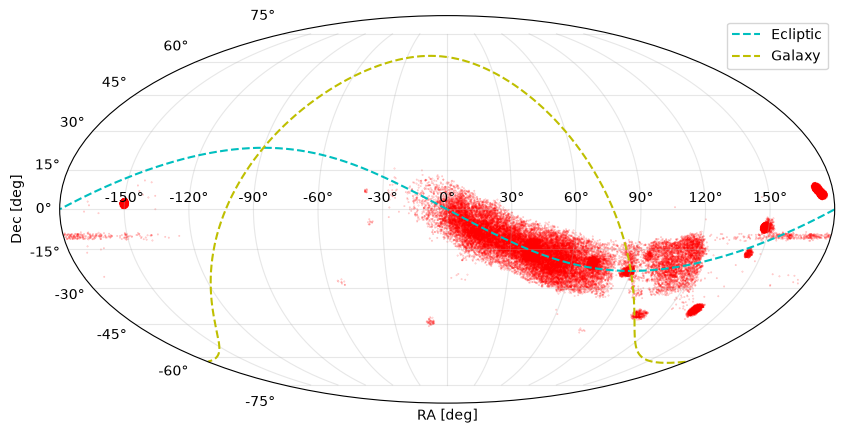

In [7]:
sample = df_sel.sample(50000)
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='mollweide')
ax.scatter(f2m(sample['ra'])*DEG, sample['dec']*DEG, s=sample['mag']*0.005, alpha=0.3, c='r')
ax.plot(*split_mollweide(ecl_coords[0], ecl_coords[1]), 'c--', label='Ecliptic')
ax.plot(*split_mollweide(gal_coords[0], gal_coords[1]), 'y--', label='Galaxy')
ax.legend()
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'scatter-observations-map.png')


Density of observations:

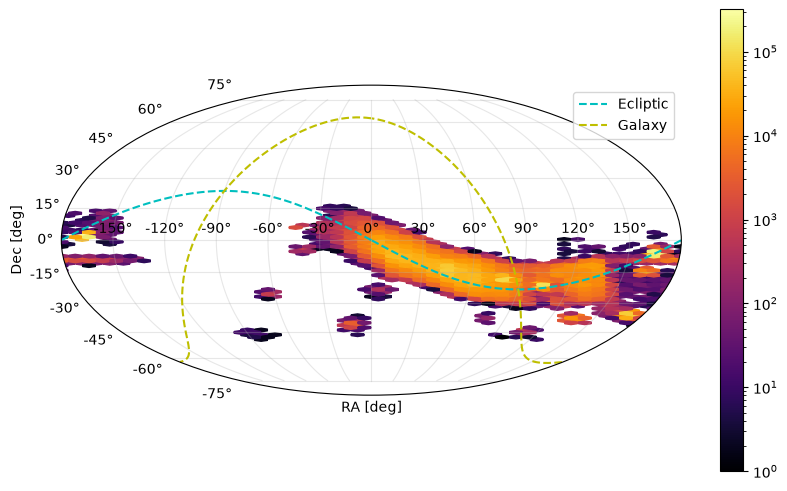

In [8]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='mollweide')

hb = ax.hexbin(f2m(df_sel['ra'])*DEG, df_sel['dec']*DEG, gridsize=50, bins='log', cmap='inferno')
fig.colorbar(hb)

ax.plot(*split_mollweide(ecl_coords[0], ecl_coords[1]), 'c--', label='Ecliptic')
ax.plot(*split_mollweide(gal_coords[0], gal_coords[1]), 'y--', label='Galaxy')
ax.legend()

ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'hexbin-observations-map.png')


## Spectra of Jorgezuluaga

In [9]:
wavelengths = {'Lg': 483, 'Lr': 622, 'Li': 755, 'Lz': 869, 'Ly': 971}
solar_color = {'Lg': 0.45, 'Lr': 0.00, 'Li': -0.12, 'Lz': -0.16, 'Ly': -0.18}
band_colors = {'Lg': '#2ca02c', 'Lr': '#d62728', 'Li': '#ff7f0e', 'Lz': '#8c564b', 'Ly': '#e377c2'}
order = ['Lg', 'Lr', 'Li', 'Lz', 'Ly']
short = {'Lg': 'g', 'Lr': 'r', 'Li': 'i', 'Lz': 'z', 'Ly': 'y'}

def wmean(m, s):
    m = np.asarray(m, float)
    s = np.asarray(s, float)
    w = 1.0 / s**2
    return np.sum(w * m) / np.sum(w), 1.0 / np.sqrt(np.sum(w))

In [10]:
obj = SBDB.query("Jorgezuluaga")
permid = obj["object"]["des"]  
provid = obj["object"].get("prov_des") 
print(f"MPC ids: {permid}  / {provid}")

MPC ids: 347940  / None


The three dashed curves are not a published spectral library. They are analytic sketches written in the next cell, normalized at the LSST $r$ effective wavelength ($\lambda_r = 622\,\mathrm{nm}$), so the asteroid can be compared by eye with the three classical taxonomic complexes (Tholen 1984; Bus & Binzel 2002; DeMeo et al. 2009). They are not the Bus–DeMeo mean spectra.

Each curve is a straight continuum anchored at $R(\lambda_r) = 1$. The S-type sketch adds a Gaussian dip for the $1\,\mu\mathrm{m}$ silicate band:

$$
R(\lambda) = 1 + s\,\frac{\lambda - 622}{\Delta\lambda} - A\exp\!\left[-\left(\frac{\lambda - \lambda_0}{w}\right)^{2}\right]
$$

- **C-type** (gray): $s = 0.05$, $\Delta\lambda = 400\,\mathrm{nm}$, $A = 0$. Slope $\approx 1.3\,\%/100\,\mathrm{nm}$. Nearly neutral continuum, as in primitive carbonaceous C-complex objects.
- **D-type** (red): $s = 0.9$, $\Delta\lambda = 400\,\mathrm{nm}$, $A = 0$. Slope $\approx 23\,\%/100\,\mathrm{nm}$. Steep red continuum and no silicate band, as in organic-rich D-types (outer belt, Trojans).
- **S-type** (gold): $s = 0.5$, $\Delta\lambda = 300\,\mathrm{nm}$ (slope $\approx 17\,\%/100\,\mathrm{nm}$), minus a Gaussian at $\lambda_0 = 950\,\mathrm{nm}$ with depth $A = 0.3$ and width $w = 150\,\mathrm{nm}$. The line is the red silicate continuum; the Gaussian stands in for Band I of olivine/pyroxene, whose minimum sits near $0.9$–$1.0\,\mu\mathrm{m}$. The Gaussian wing at $622\,\mathrm{nm}$ is negligible, so $R(622) \approx 1$.

The asteroid points use the same normalization. Same-night colors relative to $L_r$ become solar-normalized reflectance by subtracting the adopted solar color and converting magnitude to flux,

$$
\frac{R_b}{R_r} = 10^{-0.4\,\left[(m_b - m_r) - (m_b - m_r)_\odot\right]},
$$

with $(g-r)_\odot = 0.45$, $(i-r)_\odot = -0.12$, $(z-r)_\odot = -0.16$ and $(y-r)_\odot = -0.18$.

Lg: (m-mr) = 0.673 ± 0.010   R = 0.814 ± 0.007   nights = 3
Li: (m-mr) = -0.233 ± 0.016   R = 1.110 ± 0.016   nights = 2
Lz: (m-mr) = -0.261 ± 0.028   R = 1.097 ± 0.028   nights = 1
Ly: (m-mr) = -0.226 ± 0.054   R = 1.043 ± 0.052   nights = 1


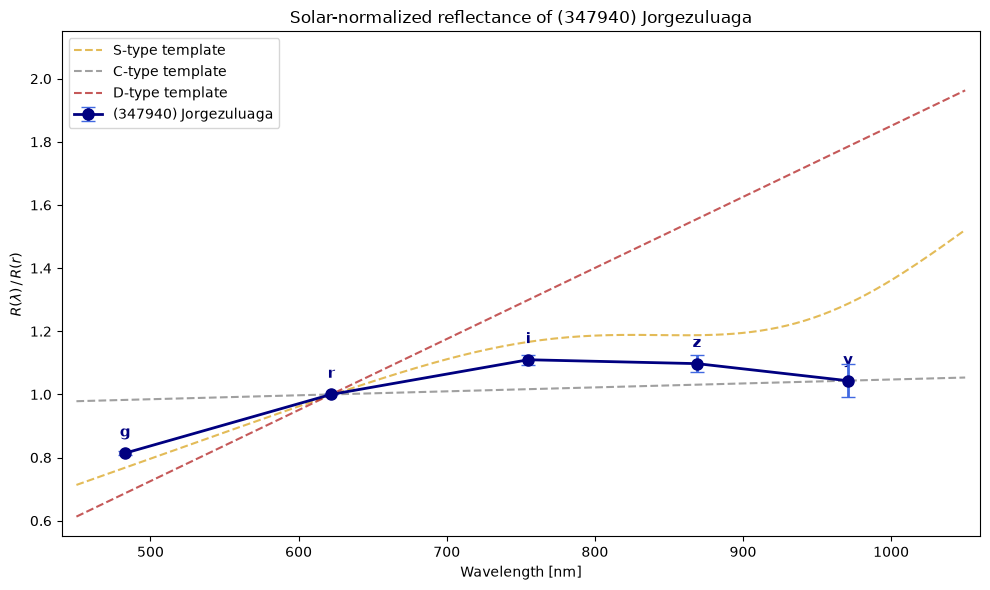

In [ ]:
table = pq.read_table(
    "data/obs_sbn_X05_full.parquet",
    columns=['permid','provid','obstime','ra','dec','mag','band','trkid','rmsmag'],
    filters=[("permid", "==", "347940")],  
)
df_obj = table.to_pandas()

df_obj['obstime'] = pd.to_datetime(df_obj['obstime'])
df_obj['mag'] = pd.to_numeric(df_obj['mag'], errors='coerce')
df_obj['rmsmag'] = pd.to_numeric(df_obj['rmsmag'], errors='coerce').fillna(0.05)
df_obj = df_obj.dropna(subset=['mag', 'band', 'obstime']).sort_values('obstime').reset_index(drop=True)
df_obj['night'] = df_obj['obstime'].dt.floor('D')

# Same-night colors relative to Lr. Drop rmsmag > 0.08 (two Ly and one Lr).
good = df_obj[df_obj['rmsmag'] <= 0.08]
color_samples = {b: [] for b in order if b != 'Lr'}
for _, g in good.groupby('night'):
    gr = g[g.band == 'Lr']
    if len(gr) == 0: continue
    mr, sr = wmean(gr['mag'], gr['rmsmag'])
    for b in color_samples:
        sub = g[g.band == b]
        if len(sub) == 0: continue
        mb, sb = wmean(sub['mag'], sub['rmsmag'])
        color_samples[b].append((mb - mr, np.sqrt(sb**2 + sr**2)))

spec = [('Lr', wavelengths['Lr'], 1.0, 0.0)]
offsets = {'Lr': 0.0}
for b, samples in color_samples.items():
    cols = np.array([s[0] for s in samples])
    errs = np.array([s[1] for s in samples])
    cmean, cerr = wmean(cols, errs)
    excess = cmean - solar_color[b]
    refl = 10.0 ** (-0.4 * excess)
    refl_err = refl * 0.4 * np.log(10.0) * cerr
    spec.append((b, wavelengths[b], refl, refl_err))
    offsets[b] = cmean
    print(f'{b}: (m-mr) = {cmean:.3f} ± {cerr:.3f}   R = {refl:.3f} ± {refl_err:.3f}   nights = {len(samples)}')
spec = sorted(spec, key=lambda x: x[1])

fig, ax = plt.subplots(figsize=(10, 6))
w = np.linspace(450, 1050, 200)

# Template spectra
ax.plot(w, 1.0 + 0.5 * (w - 622) / 300.0 - 0.3 * np.exp(-((w - 950) / 150.0) ** 2),
        '--', color='goldenrod', alpha=0.75, label='S-type template')
ax.plot(w, 1.0 + 0.05 * (w - 622) / 400.0, '--', color='gray', alpha=0.75, label='C-type template')
ax.plot(w, 1.0 + 0.9 * (w - 622) / 400.0, '--', color='firebrick', alpha=0.75, label='D-type template')

# Asteroid spectrum
ax.errorbar([s[1] for s in spec], [s[2] for s in spec], yerr=[s[3] for s in spec],
            fmt='o-', color='navy', ecolor='royalblue', elinewidth=2, capsize=5,
            markersize=8, linewidth=2, zorder=5, label='(347940) Jorgezuluaga')

for b, wl, refl, err in spec:
    ax.annotate(short[b], (wl, refl), textcoords='offset points', xytext=(0, 12),
                ha='center', fontsize=11, fontweight='bold', color='navy')

#ax.axhline(1.0, color='0.5', lw=0.8, zorder=0)
ax.set_title('Solar-normalized reflectance of (347940) Jorgezuluaga')
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel(r'$R(\lambda)\,/\,R(r)$')
ax.set_xlim(440, 1060)
ax.set_ylim(0.55, 2.15)
ax.legend(frameon=True, loc='upper left')
fig.tight_layout()
fig.savefig(fig_dir + 'jorgezuluaga_spectrum.png', dpi=150)

## Rotation light-curves

Read the data:

In [13]:
pf = pq.ParquetFile(data_file)
num_rows = pf.metadata.num_rows
num_groups = pf.num_row_groups
schema = pf.schema_arrow

Extract the data:

In [ ]:
# provid = '2025 MN37'
# provid = '2025 MM82'
provid = '2025 MM82'

obs_data = []
for batch in pf.iter_batches(batch_size=500000, columns=['permid', 'provid', 'band', 'mag', 'rmsmag', 'obstime']):
    df_b = batch.to_pandas()
    sub = df_b[df_b['provid'] == provid]
    if len(sub) > 0:
        obs_data.append(sub)

Convert the data:

In [31]:
df_obj = pd.concat(obs_data).sort_values('obstime').reset_index(drop=True)
df_obj['mag'] = pd.to_numeric(df_obj['mag'], errors='coerce')
df_obj['rmsmag'] = pd.to_numeric(df_obj['rmsmag'], errors='coerce')

t0 = df_obj['obstime'].iloc[0]
df_obj['t_days'] = (df_obj['obstime'] - t0).dt.total_seconds() / 86400.0

print(f"Total observations of Asteroid 61461: {len(df_obj)}")
print(f"Observing baseline: {(df_obj['obstime'].max() - t0).total_seconds() / 86400.0:.2f} days")
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

Total observations of Asteroid 61461: 478
Observing baseline: 9.08 days
Observations per band: {'Lr': 185, 'Lg': 97, 'Li': 85, 'g': 49, 'i': 31, 'r': 29, 'Lu': 2}


Lomb-scargle of the Lr:

In [32]:
df_r = df_obj[df_obj['band'] == 'Lr'].copy()
t_r = df_r['t_days'].values
y_r = df_r['mag'].values
dy_r = df_r['rmsmag'].fillna(0.01).values

# Frequency grid: 1.0 to 10.0 cycles/day (corresponding to periods from 2.4 to 24 hours)
freq_grid = np.linspace(1.0, 10.0, 5000)
power = LombScargle(t_r, y_r, dy_r).power(freq_grid)

best_freq = freq_grid[np.argmax(power)]
best_phot_period = 24.0 / best_freq
best_rot_period = 2.0 * best_phot_period  # Double-peaked rotational period

print(f"Peak Photometric Frequency: {best_freq:.3f} cycles/day")
print(f"Photometric Variation Period (1 peak): {best_phot_period:.2f} hours")
print(f"Derived Asteroid Rotation Period (2 peaks): {best_rot_period:.2f} hours")


Peak Photometric Frequency: 8.032 cycles/day
Photometric Variation Period (1 peak): 2.99 hours
Derived Asteroid Rotation Period (2 peaks): 5.98 hours


Now let's plot the data:

Nights:

In [41]:
nights = df_obj.obstime.dt.date.unique()
nights

array([datetime.date(2025, 4, 25), datetime.date(2025, 4, 28),
       datetime.date(2025, 4, 29), datetime.date(2025, 4, 30),
       datetime.date(2025, 5, 2), datetime.date(2025, 5, 3),
       datetime.date(2025, 5, 4)], dtype=object)

In [43]:
night = nights[0]
night

datetime.date(2025, 4, 25)

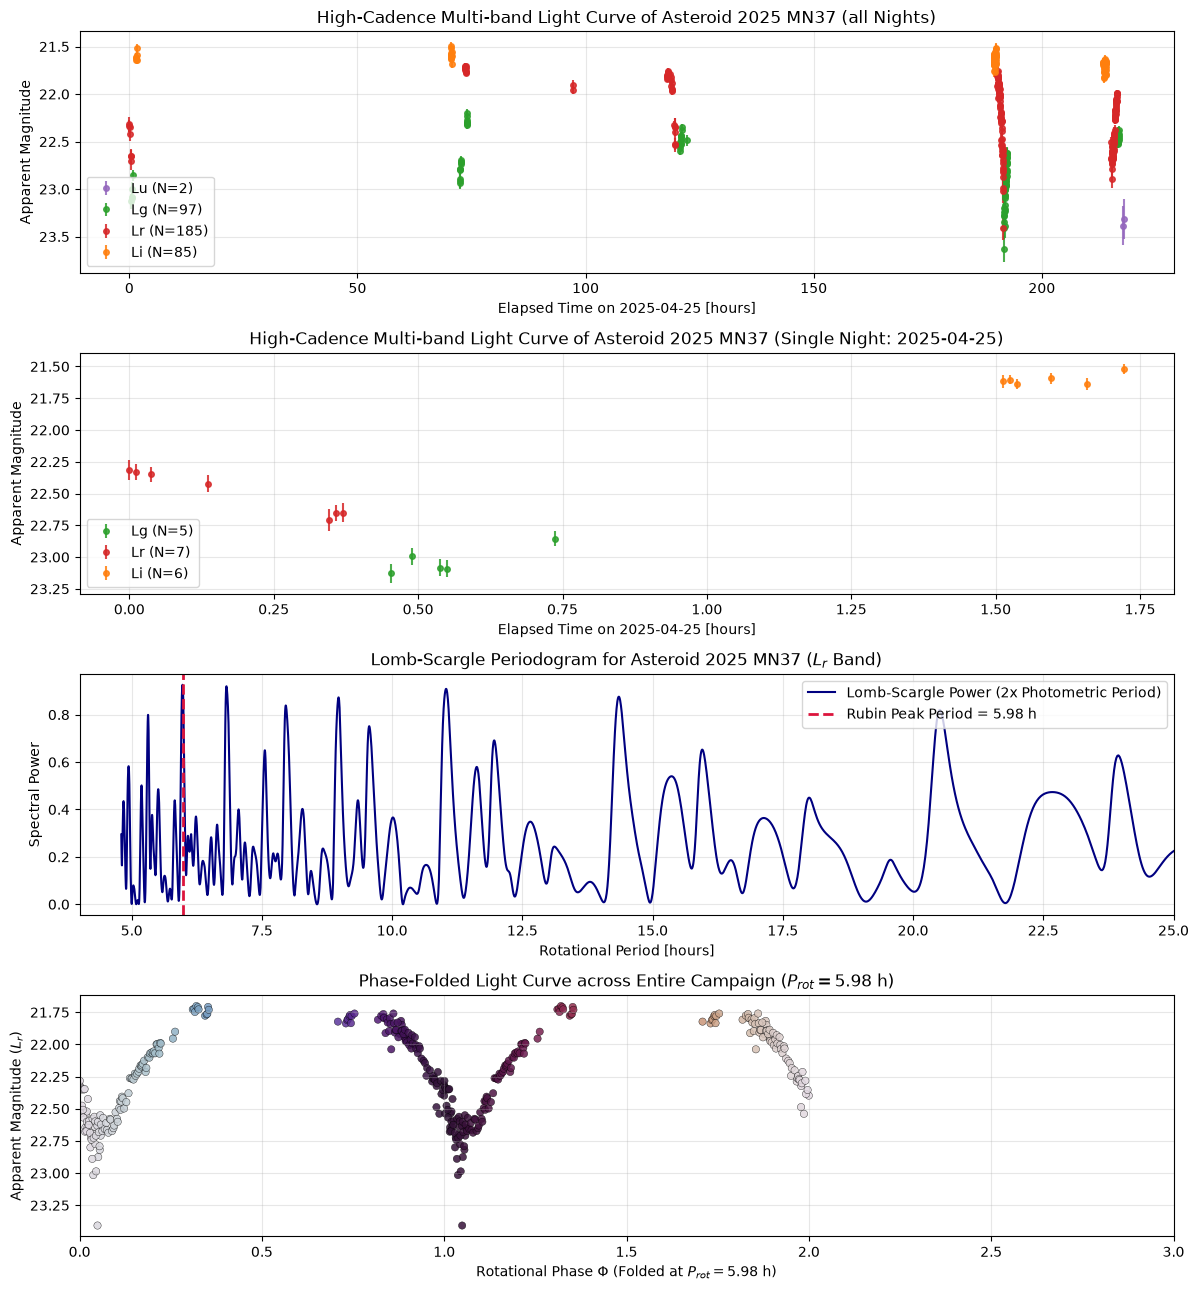

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(12, 13))

# All data
ax1 = axes[0]
night_df = df_obj.copy()
t_night_0 = night_df['obstime'].iloc[0]
night_df['t_night_h'] = (night_df['obstime'] - t_night_0).dt.total_seconds() / 3600.0
# band_colors = {'Lu': '#9467bd', 'Lg': '#2ca02c', 'Lr': '#d62728', 'Li': '#ff7f0e'}

for b in ['Lu', 'Lg', 'Lr', 'Li']:
    sb = night_df[night_df['band'] == b]
    if len(sb) > 0:
        ax1.errorbar(sb['t_night_h'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax1.invert_yaxis()
ax1.set_xlabel(f"Elapsed Time on {night} [hours]")
ax1.set_ylabel('Apparent Magnitude')
ax1.set_title(f"High-Cadence Multi-band Light Curve of Asteroid {provid} (all Nights)")
ax1.legend(loc='lower left', frameon=True)
ax1.grid(True, alpha=0.3)


# Single night
ax1 = axes[1]
night_df = df_obj[df_obj['obstime'].dt.date == night].copy()
t_night_0 = night_df['obstime'].iloc[0]
night_df['t_night_h'] = (night_df['obstime'] - t_night_0).dt.total_seconds() / 3600.0
# band_colors = {'Lu': '#9467bd', 'Lg': '#2ca02c', 'Lr': '#d62728', 'Li': '#ff7f0e'}

for b in ['Lu', 'Lg', 'Lr', 'Li']:
    sb = night_df[night_df['band'] == b]
    if len(sb) > 0:
        ax1.errorbar(sb['t_night_h'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax1.invert_yaxis()
ax1.set_xlabel(f"Elapsed Time on {night} [hours]")
ax1.set_ylabel('Apparent Magnitude')
ax1.set_title(f"High-Cadence Multi-band Light Curve of Asteroid {provid} (Single Night: {night})")
ax1.legend(loc='lower left', frameon=True)
ax1.grid(True, alpha=0.3)

# Panel B: Lomb-Scargle Periodogram
ax2 = axes[2]
period_grid_hours = (24.0 / freq_grid) * 2.0  # Converted to rotational period
ax2.plot(period_grid_hours, power, color='navy', lw=1.5, label='Lomb-Scargle Power (2x Photometric Period)')
ax2.axvline(best_rot_period, color='crimson', linestyle='--', lw=2, label=f'Rubin Peak Period = {best_rot_period:.2f} h')
ax2.set_xlabel('Rotational Period [hours]')
ax2.set_ylabel('Spectral Power')
ax2.set_title(f'Lomb-Scargle Periodogram for Asteroid {provid} ($L_r$ Band)')
ax2.set_xlim(4, 25)
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, alpha=0.3)

# Panel C: Phase-folded light curve
ax3 = axes[3]
phase = (df_r['t_days'] * 24.0 / best_rot_period) % 1.0
phase_ext = np.concatenate([phase, phase + 1.0])
mag_ext = np.concatenate([df_r['mag'], df_r['mag']])
rmsmag_ext = np.concatenate([dy_r, dy_r])

sc = ax3.scatter(phase_ext, mag_ext, c=phase_ext, cmap='twilight', s=28, edgecolor='k', lw=0.3, alpha=0.85)
ax3.invert_yaxis()
ax3.set_xlabel(rf'Rotational Phase $\Phi$ (Folded at $P_{{rot}} = {best_rot_period:.2f}$ h)')
ax3.set_ylabel('Apparent Magnitude ($L_r$)')
ax3.set_title(f'Phase-Folded Light Curve across Entire Campaign ($P_{{rot}} = {best_rot_period:.2f}$ h)')
ax3.set_xlim(0, 2)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'asteroid_lightcurve_rotation.png'), dpi=150)
plt.show()
